# 69 — Agent–environment interaction and tabular reinforcement learning

Robot learning is different from ordinary supervised learning because an agent acts in an environment, changes what happens next, and thereby influences its own future data. This notebook introduces that feedback loop with a small grid world and tabular Q-learning.

The environment is deliberately simple. Our goal is to understand the vocabulary and mechanics before adding images, neural policies, or realistic robot dynamics.

## Learning goals

- Distinguish state, observation, action, reward, policy, trajectory, and return.
- Implement a closed agent–environment interaction loop.
- Calculate discounted returns.
- Understand the Q-learning target and temporal-difference update.
- Train and visualize a tabular policy.
- Compare sparse and shaped rewards.
- Observe sensitivity to exploration and random seed.

In [1]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

SEED = 42
np.random.seed(SEED)

## 1. The agent–environment loop

At time $t$:

1. the agent receives state $s_t$;
2. its policy selects action $a_t$;
3. the environment produces reward $r_{t+1}$ and next state $s_{t+1}$;
4. the process repeats until termination.

A trajectory is

$$
\tau=(s_0,a_0,r_1,s_1,a_1,r_2,\ldots).
$$

In this fully observable grid world, the agent receives the true state: its row and column. A physical robot usually receives an observation such as an image, depth map, or joint readings rather than complete access to the underlying world state.

## 2. A small grid-world environment

The agent begins in the lower-left corner and must reach the upper-right goal while avoiding blocked cells. Actions are discrete:

| Index | Action | Change $(\Delta row,\Delta column)$ |
| --- | --- | --- |
| 0 | up | $(-1,0)$ |
| 1 | right | $(0,1)$ |
| 2 | down | $(1,0)$ |
| 3 | left | $(0,-1)$ |

An action that would cross the boundary or enter an obstacle leaves the agent in place.

### Exercise 1 — Implement the transition and reward

In [3]:
ACTION_DELTAS = np.array(
    [
        [-1, 0],
        [0, 1],
        [1, 0],
        [0, -1],
    ],
    dtype=np.int64,
)
ACTION_NAMES = ("up", "right", "down", "left")
ACTION_ARROWS = ("↑", "→", "↓", "←")


@dataclass
class GridWorld:
    height: int = 5
    width: int = 6
    start: tuple[int, int] = (4, 0)
    goal: tuple[int, int] = (0, 5)
    obstacles: tuple[tuple[int, int], ...] = (
        (1, 1),
        (1, 2),
        (2, 2),
        (3, 4),
    )
    reward_mode: str = "sparse"

    def __post_init__(self):
        if self.reward_mode not in {"sparse", "shaped"}:
            raise ValueError("reward_mode must be 'sparse' or 'shaped'")
        self.obstacle_set = set(self.obstacles)
        self.state = self.start

    def reset(self):
        self.state = self.start
        return self.state

    def manhattan_distance(self, state):
        return abs(state[0] - self.goal[0]) + abs(state[1] - self.goal[1])

    def step(self, action):
        if not 0 <= action < len(ACTION_DELTAS):
            raise ValueError("action must be an integer from 0 to 3")

        old_state = self.state
        # add the selected action delta and clip row/column to the grid.
        candidate = old_state + ACTION_DELTAS[action]
        candidate = (
            max(0, min(candidate[0], self.height - 1)),
            max(0, min(candidate[1], self.width - 1))
        )
        # obstacles block movement; otherwise accept the candidate state.
        next_state = candidate if candidate not in self.obstacle_set else old_state
        terminated = next_state == self.goal

        if self.reward_mode == "sparse":
            # give reward 1 only when the goal is reached.
            reward = 1.0 if terminated else 0.0
        else:
            # Reward progress toward the goal, charge a small step cost, and
            # add a terminal bonus. This is simple potential-based guidance.
            progress = self.manhattan_distance(old_state) - self.manhattan_distance(next_state)
            reward = 0.1 * progress - 0.01 + (1.0 if terminated else 0.0)

        self.state = next_state
        return next_state, float(reward), terminated


environment = GridWorld()
print("start:", environment.reset())
print("one step right:", environment.step(1))
assert environment.state == (4, 1)

start: (4, 0)
one step right: ((np.int64(4), np.int64(1)), 0.0, False)


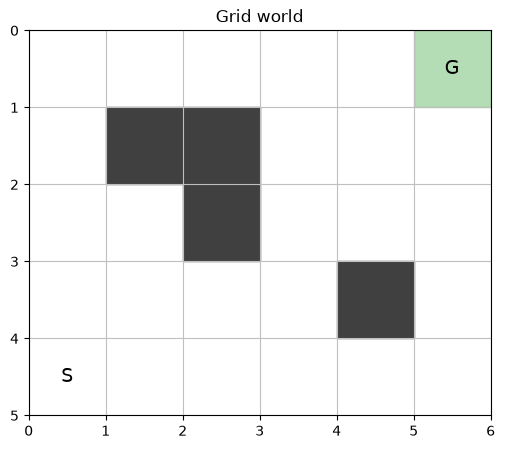

In [12]:
def plot_grid(environment, trajectory=None, axis=None, title=None):
    if axis is None:
        _, axis = plt.subplots(figsize=(6, 5))

    axis.set_xlim(0, environment.width)
    axis.set_ylim(environment.height, 0)
    axis.set_aspect("equal")
    axis.set_xticks(np.arange(environment.width + 1))
    axis.set_yticks(np.arange(environment.height + 1))
    axis.grid(color="0.75")

    for row, column in environment.obstacles:
        axis.add_patch(Rectangle((column, row), 1, 1, color="0.25"))

    start_row, start_column = environment.start
    goal_row, goal_column = environment.goal
    axis.text(start_column + 0.5, start_row + 0.5, "S", ha="center", va="center", fontsize=14)
    axis.add_patch(Rectangle((goal_column, goal_row), 1, 1, color="tab:green", alpha=0.35))
    axis.text(goal_column + 0.5, goal_row + 0.5, "G", ha="center", va="center", fontsize=14)

    if trajectory is not None:
        coordinates = np.array([(column + 0.5, row + 0.5) for row, column in trajectory])
        axis.plot(coordinates[:, 0], coordinates[:, 1], "o-", color="tab:red", linewidth=2, alpha=0.3)

    axis.set_title(title or "Grid world")
    return axis


plot_grid(environment)
plt.show()

## 3. Policies and trajectories

A policy specifies how actions are selected. A deterministic policy maps each state to one action. A stochastic policy gives a probability distribution over actions.

A random policy is poor, but it makes the closed-loop structure explicit: choose an action, pass it to the environment, observe the result, and repeat.

### Exercise 2 — Roll out a random policy

steps: 30
reached goal: False


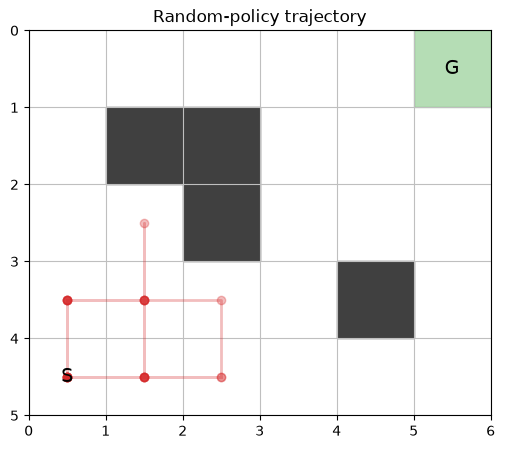

In [13]:
def random_policy(state, rng):
    del state
    return int(rng.integers(0, len(ACTION_DELTAS)))


def rollout_policy(environment, policy, rng, max_steps=50):
    state = environment.reset()
    states = [state]
    actions = []
    rewards = []

    for _ in range(max_steps):
        # select an action, step the environment, and record the result.
        action = policy(state, rng)
        next_state, reward, terminated = environment.step(action)

        actions.append(action)
        rewards.append(reward)
        states.append(next_state)
        state = next_state
        if terminated:
            break

    return {"states": states, "actions": actions, "rewards": rewards, "terminated": terminated}


random_trajectory = rollout_policy(
    GridWorld(), random_policy, np.random.default_rng(SEED), max_steps=30
)
print("steps:", len(random_trajectory["actions"]))
print("reached goal:", random_trajectory["terminated"])
plot_grid(GridWorld(), random_trajectory["states"], title="Random-policy trajectory")
plt.show()

## 4. Reward and discounted return

Reward describes the immediate feedback from one transition. Return summarizes the rewards that follow a particular time step, so it measures the longer-term result of a decision rather than only what happened immediately.

$$
G_t=r_{t+1}+\gamma r_{t+2}+\gamma^2r_{t+3}+\cdots.
$$

For example, suppose three actions produce rewards $[0,0,1]$: the first two actions move toward the goal, and the third reaches it. Looking only at immediate rewards makes the first two actions appear useless. With $\gamma=0.9$, their returns are $[0.81,0.9,1.0]$, so the eventual success also gives credit to the earlier actions that made it possible.

The discount factor $0\leq\gamma\leq1$ determines how strongly distant rewards matter. With $\gamma=0$, only the immediate reward matters; values closer to one preserve more of the future reward. Returns can be calculated efficiently backward:

$$
G_t=r_{t+1}+\gamma G_{t+1}.
$$

This recursive form says: the return now equals the next immediate reward plus the discounted return from the next time step. Q-learning later uses the same idea, but replaces the unknown future return with its current estimate $\max_{a'}Q(s',a')$.

### Exercise 3 — Calculate every return in a trajectory

In [15]:
def discounted_returns(rewards, gamma):
    if not 0 <= gamma <= 1:
        raise ValueError("gamma must be between 0 and 1")
    returns = np.zeros(len(rewards), dtype=np.float64)
    running_return = 0.0
    # iterate backward, update running_return, and store each value.
    for i in reversed(range(len(rewards))):
        running_return = rewards[i] + gamma * running_return
        returns[i] = running_return
    return returns


example_rewards = [0.0, 0.0, 1.0]
example_returns = discounted_returns(example_rewards, gamma=0.9)
print(example_returns)
np.testing.assert_allclose(example_returns, [0.81, 0.9, 1.0])

[0.81 0.9  1.  ]


## 5. Q-values and temporal-difference learning

$Q(s,a)$ estimates the future return obtained by taking action $a$ in state $s$ and then behaving well afterward. It therefore tells the agent how promising a particular local decision appears in terms of its longer-term consequences. Tabular Q-learning stores one number for every state–action pair. In this grid, the Q-table has shape $(5,6,4)$: four action values for every grid cell.

The table is allocated **before** learning, usually with every value initialized to zero. Its useful values are created **during** learning as the agent experiences transitions. Afterward, a greedy policy can select the action with the largest value, $\arg\max_a Q(s,a)$.

For a nonterminal transition, the target is

$$
y=r+\gamma\max_{a'}Q(s',a').
$$

For a terminal transition, no future action follows, so $y=r$. The update moves the current estimate toward the target:

$$
Q(s,a)\leftarrow Q(s,a)+\alpha\left(y-Q(s,a)\right).
$$

The difference $y-Q(s,a)$ is the temporal-difference error.

Sparse rewards can still produce useful Q-values. Imagine a path $A\rightarrow B\rightarrow Goal$ where only entering the goal gives reward $1$. The final action first teaches the agent that the useful action at $B$ has value near $1$. On a later visit, the transition from $A$ has immediate reward zero, but its target can be positive because the next state is now valuable:

$$
0+\gamma\max_{a'}Q(B,a')=\gamma.
$$

In this way, the terminal reward gradually propagates backward through earlier states. Before the agent discovers the goal, however, every observed reward and Q-value may remain zero. This is why exploration is essential and why sparse-reward problems become difficult when successful trajectories are rare.

### Exercise 4 — Implement one Q-learning update

In [19]:
def q_learning_update(q_values, state, action, reward, next_state, terminated, alpha, gamma):
    current_value = q_values[state[0], state[1], action]
    # omit future value after termination; otherwise use the best next action.
    target = reward + (0.0 if terminated else gamma * np.max(q_values[next_state[0], next_state[1]]))
    td_error = target - current_value
    # update exactly one state-action entry.
    q_values[state[0], state[1], action] += alpha * td_error
    return float(td_error)

# height, width, num_actions = 5, 6, 4
test_q_values = np.zeros((5, 6, 4), dtype=np.float64)
test_q_values[4, 1] = [0.2, 0.5, 0.1, 0.0]
test_error = q_learning_update(
    test_q_values,
    state=(4, 0),
    action=1,
    reward=0.0,
    next_state=(4, 1),
    terminated=False,
    alpha=0.5,
    gamma=0.9,
)
print("TD error:", test_error)
print("updated value:", test_q_values[4, 0, 1])
np.testing.assert_allclose(test_error, 0.45)
np.testing.assert_allclose(test_q_values[4, 0, 1], 0.225)

TD error: 0.45
updated value: 0.225


## 6. Exploration and Q-learning

A purely greedy agent cannot learn about actions it never tries. An $\epsilon$-greedy policy chooses a random action with probability $\epsilon$ and the currently best-known action otherwise.

### Exercise 5 — Train a tabular Q-learning agent

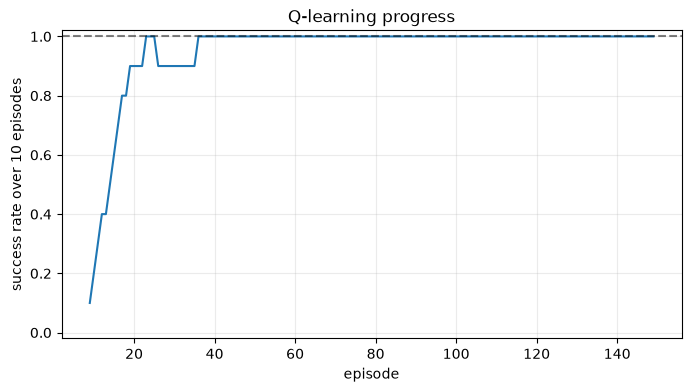

In [41]:
def train_q_learning(
    environment,
    number_episodes=150,
    alpha=0.25,
    gamma=0.95,
    epsilon=0.2,
    max_steps=100,
    seed=SEED,
):
    rng = np.random.default_rng(seed)
    q_values = np.zeros((environment.height, environment.width, len(ACTION_DELTAS)))
    episode_returns = []
    episode_lengths = []
    episode_successes = []

    for _ in range(number_episodes):
        state = environment.reset()
        total_reward = 0.0
        terminated = False

        for step_index in range(max_steps):
            # choose randomly with probability epsilon, otherwise greedily.
            action = rng.integers(0, len(ACTION_DELTAS)) if rng.random() < epsilon else np.argmax(q_values[state[0], state[1]])
            next_state, reward, terminated = environment.step(action)
            # apply q_learning_update to this transition.
            q_learning_update(
                q_values,
                state=state,
                action=action,
                reward=reward,
                next_state=next_state,
                terminated=terminated,
                alpha=alpha,
                gamma=gamma,
            )

            total_reward += reward
            state = next_state
            if terminated:
                break

        episode_returns.append(total_reward)
        episode_lengths.append(step_index + 1)
        episode_successes.append(terminated)

    history = {
        "returns": np.asarray(episode_returns),
        "lengths": np.asarray(episode_lengths),
        "successes": np.asarray(episode_successes),
    }
    return q_values, history


q_values, training_history = train_q_learning(GridWorld())

window = 10
moving_success = np.convolve(
    training_history["successes"].astype(float),
    np.ones(window) / window,
    mode="valid",
)
plt.figure(figsize=(8, 4))
plt.plot(np.arange(window - 1, len(training_history["successes"])), moving_success)
plt.axhline(1.0, color="black", linestyle="--", alpha=0.5)
plt.ylim(-0.02, 1.02)
plt.xlabel("episode")
plt.ylabel(f"success rate over {window} episodes")
plt.title("Q-learning progress")
plt.grid(alpha=0.25)
plt.show()

### Learning rate $\alpha$ versus discount factor $\gamma$

These parameters have different jobs. The discount factor $\gamma$ determines how strongly an expected **future reward** contributes to the target:

$$
y=r+\gamma\max_{a'}Q(s',a').
$$

The learning rate $\alpha$ then determines how far the current Q-value moves toward that target in one update:

$$
Q(s,a)\leftarrow Q(s,a)+\alpha\bigl(y-Q(s,a)\bigr).
$$

Thus, $\gamma$ means *how much should future consequences matter?*, whereas $\alpha$ means *how much should this new experience change the current estimate?* In this experiment, $\gamma=0.95$ preserves most of a delayed goal reward per step, while $\alpha=0.25$ moves a Q-value one quarter of the distance toward each new target. Exploration is controlled separately by $\epsilon$.

### Exercise 6 — Visualize and evaluate the greedy policy

The state value implied by the Q-table is $V(s)=\max_a Q(s,a)$. The greedy policy chooses the maximizing action. Visualizing both helps reveal whether the learned values and behavior agree.

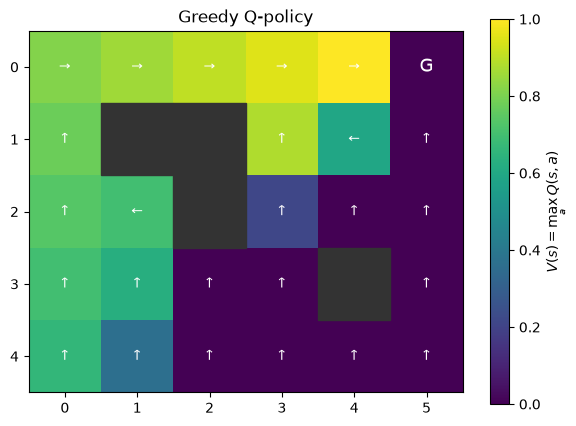

greedy steps: 9
reached goal: True


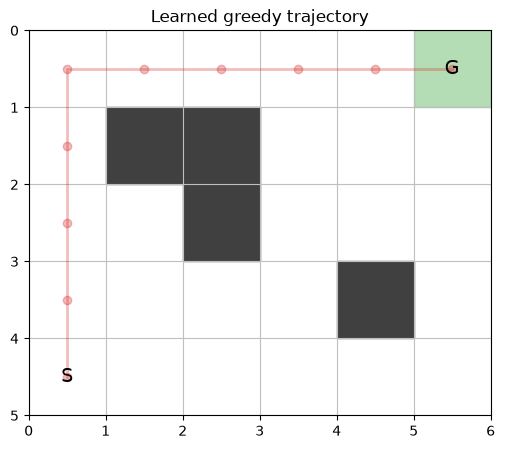

In [43]:
def plot_q_policy(environment, q_values, axis=None, title="Greedy Q-policy"):
    if axis is None:
        _, axis = plt.subplots(figsize=(7, 5))
    state_values = q_values.max(axis=2)
    image_artist = axis.imshow(state_values, cmap="viridis")

    for row in range(environment.height):
        for column in range(environment.width):
            state = (row, column)
            if state in environment.obstacle_set:
                axis.add_patch(Rectangle((column - 0.5, row - 0.5), 1, 1, color="0.2"))
            elif state == environment.goal:
                axis.text(column, row, "G", ha="center", va="center", color="white", fontsize=13)
            else:
                # TODO: choose the greedy action and draw its arrow.
                action = int(np.argmax(q_values[row, column]))
                axis.text(column, row, ACTION_ARROWS[action], ha="center", va="center", color="white")

    axis.set_xticks(range(environment.width))
    axis.set_yticks(range(environment.height))
    axis.set_title(title)
    plt.colorbar(image_artist, ax=axis, label=r"$V(s)=\max_a Q(s,a)$")
    return axis


def greedy_q_policy(q_values):
    def policy(state, rng):
        del rng
        return int(np.argmax(q_values[state[0], state[1]]))
    return policy


plot_q_policy(GridWorld(), q_values)
plt.show()

greedy_trajectory = rollout_policy(
    GridWorld(), greedy_q_policy(q_values), np.random.default_rng(SEED), max_steps=50
)
print("greedy steps:", len(greedy_trajectory["actions"]))
print("reached goal:", greedy_trajectory["terminated"])
plot_grid(GridWorld(), greedy_trajectory["states"], title="Learned greedy trajectory")
plt.show()

## 7. Controlled experiments

Sparse rewards directly describe task success but can make useful experience rare. Shaped rewards provide denser guidance but may change behavior in unintended ways if they do not faithfully represent the true goal.

Exploration also creates a trade-off. Too little exploration can preserve a poor policy; too much prevents the agent from exploiting what it learned.

### Exercise 7 — Compare reward design and exploration

Train several seeds for each configuration. Report the final-window success rate rather than selecting the luckiest run.

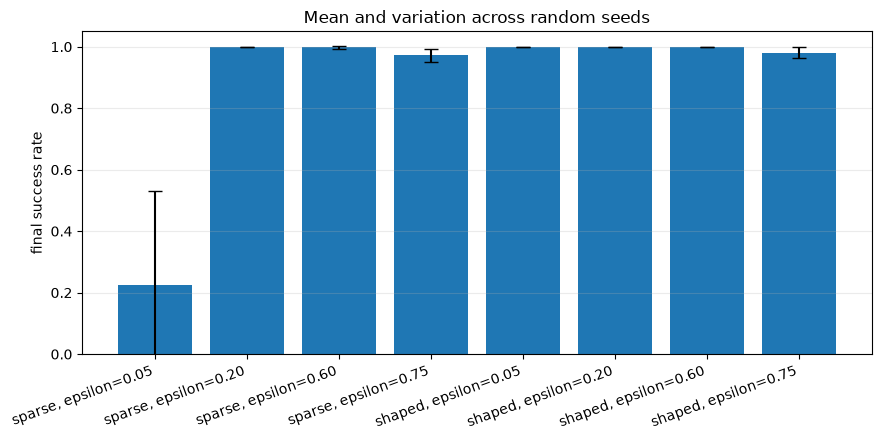

sparse, epsilon=0.05        : 0.226 ± 0.306
sparse, epsilon=0.20        : 1.000 ± 0.000
sparse, epsilon=0.60        : 0.998 ± 0.004
sparse, epsilon=0.75        : 0.972 ± 0.021
shaped, epsilon=0.05        : 1.000 ± 0.000
shaped, epsilon=0.20        : 1.000 ± 0.000
shaped, epsilon=0.60        : 1.000 ± 0.000
shaped, epsilon=0.75        : 0.980 ± 0.018


In [55]:
configurations = {
    "sparse, epsilon=0.05": ("sparse", 0.05),
    "sparse, epsilon=0.20": ("sparse", 0.20),
    "sparse, epsilon=0.60": ("sparse", 0.60),
    "sparse, epsilon=0.75": ("sparse", 0.75),
    "shaped, epsilon=0.05": ("shaped", 0.05),
    "shaped, epsilon=0.20": ("shaped", 0.20),
    "shaped, epsilon=0.60": ("shaped", 0.60),
    "shaped, epsilon=0.75": ("shaped", 0.75),
}
experiment_seeds = (3, 17, 42, 91, 123)
final_window = 100
experiment_results = {}

for configuration_name, (reward_mode, epsilon) in configurations.items():
    seed_success_rates = []
    for seed in experiment_seeds:
        # train this configuration and measure final-window success.
        history = train_q_learning(GridWorld(reward_mode=reward_mode), epsilon=epsilon, seed=seed, number_episodes=150)[1]
        success_rate = history["successes"][-final_window:].mean()
        seed_success_rates.append(success_rate)
    experiment_results[configuration_name] = np.asarray(seed_success_rates)

means = [values.mean() for values in experiment_results.values()]
standard_deviations = [values.std() for values in experiment_results.values()]

figure, axis = plt.subplots(figsize=(9, 4.5))
axis.bar(range(len(configurations)), means, yerr=standard_deviations, capsize=5)
axis.set_xticks(range(len(configurations)), configurations.keys(), rotation=20, ha="right")
axis.set_ylim(0, 1.05)
axis.set_ylabel("final success rate")
axis.set_title("Mean and variation across random seeds")
axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

for name, values in experiment_results.items():
    print(f"{name:28s}: {values.mean():.3f} ± {values.std():.3f}")

## 8. What this grid world leaves out

A real robot does not receive a small exact state index. It may have partial and noisy observations, continuous actions, delayed effects, changing surroundings, safety constraints, and expensive physical interactions. A Q-table also cannot scale to images or large continuous state spaces.

Nevertheless, the same conceptual loop remains:

$$
\text{observe}\rightarrow\text{act}\rightarrow\text{change the world}\rightarrow\text{receive feedback}.
$$

Later practice will replace the table with learned policies and dynamics models.

## Reflection

1. Why is the data distribution in reinforcement learning influenced by the policy itself?

   _Your answer:_ The policy selects actions, and those actions determine which states the agent visits. Therefore, changing the policy also changes the distribution of training experience.

2. What is the difference between an immediate reward and a return?

   _Your answer:_ An immediate reward evaluates one transition. A return is the discounted sum of rewards from that transition onward, so it measures longer-term consequences.

3. Why is there no bootstrapped future value in the Q-learning target after a terminal transition?

   _Your answer:_ After a terminal transition, the episode has ended and no future rewards or actions remain. Therefore, the target is only the terminal reward, with future value treated as zero.

4. What role does $\epsilon$ play in an $\epsilon$-greedy policy?

   _Your answer:_ At each decision, $\epsilon$ is the probability of selecting a random exploratory action instead of the currently greedy action.

5. How can reward shaping help, and how can it be dangerous?

   _Your answer:_ Reward shaping provides intermediate feedback that can make sparse-reward learning faster. However, a poorly designed shaped reward may encourage unintended shortcuts or behavior that maximizes the shaped reward without completing the intended task.

6. Why is training loss or average reward from one run insufficient evidence that a robot-learning method is reliable?

   _Your answer:_ One run may be unusually successful or unsuccessful because of exploration, initialization, and environment randomness. Reliability requires evaluation across multiple seeds, episodes, starting conditions, and relevant environments, including examination of failure and safety behavior.